# 数値計算演習3：球対称ポテンシャルと時間積分法

**Ryden, *Celestial and Stellar Dynamics*, §7.1**

Notebook 1–2 と同じ Plummer 球を使い、星の位置と速度を時間積分します。時間積分法の誤差を調べるため、加速度は解析式で与えます。Notebook 2 の数値ポテンシャルを読み込む計算ではありません。

宇宙流体・重力多体系シミュレーションに進む準備として、時間積分とその検証を学びます。補足で自己重力系や流体への関係を紹介しますが、以下の数値実験は固定された Plummer ポテンシャル中の軌道のままです。

## 学習目標

1. 運動方程式を、位置と速度を未知数とする1階の常微分方程式系に書き換え、初期値問題として設定できる。
2. Euler 法、RK4、リープフロッグ法の更新の考え方を説明し、時間ループとして実装できる。
3. 円軌道の解析解との比較と時間刻みを変えた収束試験から、時間積分法の誤差と収束次数を評価できる。
4. エネルギーと角運動量の変化を用いて数値軌道を診断し、保存量だけでは位置の精度を判断できないことを説明できる。
5. 収束次数と長時間積分での保存量の振る舞いを区別し、必要な精度・積分時間・計算コストに応じて時間積分法を選ぶ際の考え方を説明できる。

この Notebook では、本文の学習目標に加えて、シンプレクティック性と宇宙流体計算の RK2・RK3 を発展的な補足として扱います。軸対称・非軸対称の軌道は Notebook C、2次元 Poisson 方程式は Notebook B に分けています。

時間積分法は幸谷『Python数値計算プログラミング』第13章、リープフロッグ法の長時間挙動は松本ほか『輻射電磁流体シミュレーションの基礎』§9.6を参照します。


## 実行順序とテキストとの対応

この Notebook は単独で、上から順に実行できます。他の Notebook の実行結果は必要ありません。設定を変更した場合は、カーネルを再起動して全セルを実行してください。

対応する本文は第3章です。球対称モデルの準備、初期値問題、3つの積分法、円軌道の比較、収束、保存量、長時間比較の順に進みます。

| テキストの内容 | Notebook 3 の節名 |
| --- | --- |
| Plummer 球と単位 | 「球対称ポテンシャル：Plummer モデル」 |
| 初期値問題 | 「初期値問題としての運動方程式」 |
| Euler・RK4・リープフロッグ法 | 「3つの時間積分法」 |
| 円軌道と収束試験 | 「円軌道による時間積分法の比較」「時間積分法の収束次数」 |
| 自己重力系・計算コストとの関係（補足） | 「初期値問題としての運動方程式」「3つの時間積分法」中の説明 |
| シンプレクティック性／宇宙流体計算の時間積分（補足） | 「シンプレクティック積分法」「宇宙流体計算の時間積分 — RK2 と RK3」 |
| 保存量と長時間計算 | 「エネルギーと角運動量の保存」「RK4 とリープフロッグ法の長時間挙動」 |



In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = 1.0

OI = {
    "orange": "#E69F00",
    "sky": "#56B4E9",
    "green": "#009E73",
    "yellow": "#F0E442",
    "blue": "#0072B2",
    "vermillion": "#D55E00",
    "purple": "#CC79A7",
    "black": "#000000",
}

plt.rcParams["figure.figsize"] = (6.5, 4.5)
plt.rcParams["font.size"] = 11


# 1. 球対称ポテンシャル：Plummer モデル

Ryden §7.1 では、時間に依存しない球対称ポテンシャルにおいて**比角運動量（specific angular momentum）**が保存し、軌道が1つの平面内に閉じ込められることを示しています。また、**比エネルギー（specific energy）**も保存します。

Notebook 1–2 で扱った Plummer ポテンシャルを使います。

$$
\Phi(r)
=
-\frac{GM}{\sqrt{r^2+a^2}},
$$

$$
\mathbf{g}
=
-\frac{GM}{(r^2+a^2)^{3/2}}\mathbf{r}.
$$

比エネルギーは
$$
E=\frac{1}{2}v^2+\Phi(r),
$$
比角運動量は
$$
\mathbf{L}=\mathbf{r}\times\mathbf{v}
$$
です。

### 補足：Plummer 型ソフトニングとの関係

このポテンシャルは、無衝突系を扱う重力 $N$ 体計算で用いられる**Plummer 型ソフトニング（softening）**と同じ関数形を持つ（参考：松本ほか『輻射電磁流体シミュレーションの基礎』）。
粒子間距離を $r$、粒子質量を $m$ とし、ポテンシャルを $-Gm/\sqrt{r^2+\epsilon^2}$ とすると、$\epsilon>0$ なら $r\to0$ でも重力加速度は発散しない。
ただし、本章の $a$ は質量モデル全体のスケール半径であり、$\epsilon$ は粒子間の重力を平滑化する長さです。
同じ関数形に現れるが、両者の役割は異なる。

### 無次元単位

質量単位を $M$、長さ単位を $a$ とすると、時間・速度・ポテンシャルの単位は
$$
 t_\ast=\sqrt{\frac{a^3}{GM}},\qquad v_\ast=\sqrt{\frac{GM}{a}},\qquad\Phi_\ast=\frac{GM}{a}
$$
です。以下では $G=M=a=1$ とします。数値結果を物理単位に戻すときは、それぞれの基準量を掛けます。

以下の関数では `G`, `M`, `a` を明示的に引数として渡します。`phi_plummer_pos` の `np.sum(x**2, axis=-1)` は、位置ベクトルの各成分の二乗和を計算します。`axis=-1` は配列の最後の軸に沿って和を取る指定で、各行が1つの位置ベクトルである配列からも、それぞれの位置のポテンシャルを求められます。`acc_plummer` は1つの位置ベクトルから加速度を求めます。`acc_plummer_model(x)` は、設定済みの `G, M, a` を渡し、位置 `x` だけから加速度を求める時間積分用の補助関数です。


In [2]:
M = 1.0
a = 1.0

def phi_plummer_pos(x, G, M, a):
    r2 = np.sum(np.asarray(x)**2, axis=-1)
    return -G * M / np.sqrt(r2 + a**2)

def acc_plummer(x, G, M, a):
    x = np.asarray(x)
    r2 = np.dot(x, x)
    return -G * M * x / (r2 + a**2)**1.5

def energy_plummer(x, v, G, M, a):
    return 0.5 * np.sum(v**2, axis=1) + phi_plummer_pos(x, G, M, a)

def angular_momentum_z(x, v):
    return x[:, 0] * v[:, 1] - x[:, 1] * v[:, 0]


def acc_plummer_model(x):
    """初期条件・解析解と同じ G, M, a を加速度にも渡す。"""
    return acc_plummer(x, G, M, a)



## 円軌道の初期条件と解析解

半径 $r_0$ の円軌道では
$$
\Omega^2
=
\frac{GM}{(r_0^2+a^2)^{3/2}},
$$
なので
$$
v_{\rm circ}=\Omega r_0.
$$

初期条件を
$$
(x,y)=(r_0,0),
\qquad
(v_x,v_y)=(0,v_{\rm circ})
$$
とすると、
$$
x(t)=r_0\cos(\Omega t),
\qquad
y(t)=r_0\sin(\Omega t)
$$
が解析解です。

この解析解を使って、常微分方程式ソルバーの収束次数を直接測定します。実際の収束試験では、円軌道を90度進んだ時刻 $T_0/4$ を終端時刻として使います。


初期条件・周期・エネルギー・加速度は同じ `G`, `M`, `a` を使います。時間積分器へは、これらを明示的に渡す `acc_plummer_model` を入力します。例えば `M=2` へ変更した場合も、設定後に全セルを再実行すれば同じモデルを検証できます。

In [3]:
r0 = 1.0
Omega0 = np.sqrt(G * M / (r0**2 + a**2)**1.5)
vc0 = Omega0 * r0
T0 = 2.0 * np.pi / Omega0

x0 = np.array([r0, 0.0])
v0 = np.array([0.0, vc0])

print(f"Omega       = {Omega0:.8f}")
print(f"v_circ      = {vc0:.8f}")
print(f"軌道周期       = {T0:.8f}")


Omega       = 0.59460356
v_circ      = 0.59460356
軌道周期       = 10.56701600



# 2. 初期値問題としての運動方程式

位置 $\mathbf{x}$ と速度 $\mathbf{v}$ に対して、
$$
\frac{d\mathbf{x}}{dt}=\mathbf{v},
\qquad
\frac{d\mathbf{v}}{dt}=-\nabla\Phi(\mathbf{x})
$$
です。

状態ベクトルを
$$
\mathbf{y}
=
\begin{pmatrix}
\mathbf{x}\\
\mathbf{v}
\end{pmatrix}
$$
とまとめると、
$$
\frac{d\mathbf{y}}{dt}
=
\mathbf{f}(\mathbf{y})
$$
という1階の常微分方程式系になります。

この形にすると、一般的な常微分方程式ソルバーを使って軌道を時間積分できます。

初期位置 $\mathbf{x}(0)=\mathbf{x}_0$ と初期速度 $\mathbf{v}(0)=\mathbf{v}_0$ を指定し、その後の状態を求める初期値問題です。

以下の時間積分関数では、加速度を計算する関数を `acc_func` という引数として受け取ります。Plummer 球を積分するときには `acc_plummer_model` を渡します。こうすると、時間積分法は変更せず、異なる重力場の関数にも利用できます。

**自己重力系との違い。** 自己重力の $N$ 体計算では、各粒子の加速度を全粒子の配置から求めるため、粒子の運動に伴って重力場も変化する。
全粒子の位置と速度をまとめれば同じ常微分方程式系の形で書けるが、粒子同士の運動は結びついており、各粒子を独立した固定場中の軌道として積分するわけではない（参考：富阪ほか編『シミュレーション天文学』）。



# 3. 3つの時間積分法

## 3.1 Euler 法

幸谷 第13章の最も基本的な方法です。
$$
\mathbf{y}_{n+1}
=
\mathbf{y}_n
+
\Delta t\,\mathbf{f}(\mathbf{y}_n).
$$

ステップの初めの値が厳密であるとして、1ステップで生じる誤差を局所打ち切り誤差と呼びます。Euler 法では $O(\Delta t^2)$ です。
固定した終端時刻まで積分したときの大域誤差（global error）は一般に
$$
O(\Delta t)
$$
です。

## 3.2 古典的4次 Runge–Kutta 法

$$
\begin{aligned}
\mathbf{k}_1 &= \mathbf{f}(\mathbf{y}_n),\\
\mathbf{k}_2 &= \mathbf{f}\left(\mathbf{y}_n+\frac{\Delta t}{2}\mathbf{k}_1\right),\\
\mathbf{k}_3 &= \mathbf{f}\left(\mathbf{y}_n+\frac{\Delta t}{2}\mathbf{k}_2\right),\\
\mathbf{k}_4 &= \mathbf{f}\left(\mathbf{y}_n+\Delta t\,\mathbf{k}_3\right),
\end{aligned}
$$

$$
\mathbf{y}_{n+1}
=
\mathbf{y}_n
+
\frac{\Delta t}{6}
(\mathbf{k}_1+2\mathbf{k}_2+2\mathbf{k}_3+\mathbf{k}_4).
$$

大域誤差は
$$
O(\Delta t^4)
$$
です。

RK4 法は1ステップで右辺を4回評価します。時間積分法を選ぶ際には、必要な精度だけでなく計算コストも考える必要があります。例えば、$N_{\rm p}$ 個の粒子間の重力を直接計算する重力多体系では、全粒子対の重力を評価するため、1回の加速度計算に $O(N_{\rm p}^2)$ の計算量がかかります（参考：富阪ほか編『シミュレーション天文学』）。このような計算では、加速度の評価回数も重要です。

## 3.3 リープフロッグ法

本章のように加速度が位置だけで決まる場合、運動方程式
$$
\ddot{\mathbf{x}}=\mathbf{g}(\mathbf{x})
$$
は、次の2つの一階微分方程式に分けられます。
$$
\dot{\mathbf{x}}=\mathbf{v},\qquad \dot{\mathbf{v}}=\mathbf{g}(\mathbf{x}).
$$
位置を固定して速度だけを更新する操作を**キック（kick）**、速度を固定して位置だけを更新する操作を**ドリフト（drift）**と呼びます。速度の変化率が位置だけで決まり、位置の変化率が速度だけで決まる性質を利用した方法です。

リープフロッグ法には、キック–ドリフト–キック（KDK）形式と、ドリフト–キック–ドリフト（DKD）形式があります。どちらも2次精度です。本章では、位置の更新を2つの半ステップの速度更新ではさむ対称的な**KDK形式**を使います。更新式は
$$
\begin{aligned}
\mathbf{v}_{n+1/2}
&=
\mathbf{v}_n+\frac{\Delta t}{2}\mathbf{g}(\mathbf{x}_n),\\
\mathbf{x}_{n+1}
&=
\mathbf{x}_n+\Delta t\,\mathbf{v}_{n+1/2},\\
\mathbf{v}_{n+1}
&=
\mathbf{v}_{n+1/2}
+\frac{\Delta t}{2}\mathbf{g}(\mathbf{x}_{n+1}).
\end{aligned}
$$

KDK形式では、速度を半ステップ、位置を1ステップ、速度をさらに半ステップ更新し、全体で時刻 $t_n$ から $t_{n+1}=t_n+\Delta t$ まで進みます。

位置更新は2次までの Taylor 展開、速度更新は加速度の台形積分に対応します。滑らかな加速度と固定時間刻みのもとで、局所打ち切り誤差は $O(\Delta t^3)$、固定した終端時刻までの大域誤差は $O(\Delta t^2)$ です。長時間の保存量の振る舞いは、第7節で扱います。

**加速度の評価回数。** 本Notebookでは、各ステップの最初と最後に加速度を計算します。しかし、前のステップの最後に求めた加速度は次のステップの最初にも使えるため、保存して再利用すれば計算回数を減らせます。ここでは更新式との対応を分かりやすくするため、加速度を毎回計算しています。


### 実装確認：1ステップの更新

配列へ全時刻を保存する前に、$\boldsymbol a(\boldsymbol x)=-\boldsymbol x$、$\boldsymbol x_n=(1,0)$、$\boldsymbol v_n=(0,1)$、$\Delta t=0.1$ の1ステップを確認します。Euler 法では $\boldsymbol x_{n+1}=(1,0.1)$、$\boldsymbol v_{n+1}=(-0.1,1)$ です。

**自分で書く部分：** 同じ入力からリープフロッグ法の3操作を書いてください。出力は `x_lf_step`, `v_lf_step` とします。期待値はそれぞれ $(0.995,0.1)$、$(-0.09975,0.995)$ です。この確認をした後で、完成した積分器の時間ループを読みます。

**導出：テキスト第3章「Euler 法」「リープフロッグ法」。**

In [4]:
def acc_demo(x):
    return -np.asarray(x, dtype=float)

x_step = np.array([1.0, 0.0])
v_step = np.array([0.0, 1.0])
dt_step = 0.1
# 両方の更新に、更新前の x_step と v_step を使う。
x_euler_step = x_step + dt_step * v_step
v_euler_step = v_step + dt_step * acc_demo(x_step)
print("Euler 法の1ステップ：位置", x_euler_step, "速度", v_euler_step)
np.testing.assert_allclose(x_euler_step, [1.0, 0.1])
np.testing.assert_allclose(v_euler_step, [-0.1, 1.0])
# 新しいセルでリープフロッグ法の1ステップを書き、本文中の期待値と比較してください。

Euler 法の1ステップ：位置 [1.  0.1] 速度 [-0.1  1. ]


In [5]:
def integrate_euler(acc_func, x0, v0, dt, nstep):
    """陽的 Euler 法で位置 x と速度 v を nstep 回更新する。"""

    # 整数のリストや配列が渡されても、時間発展で小数を保持できるよう float 配列に変換する。
    x0 = np.asarray(x0, dtype=float)
    v0 = np.asarray(v0, dtype=float)
    ndim = len(x0)

    x = np.empty((nstep + 1, ndim))
    v = np.empty((nstep + 1, ndim))
    x[0], v[0] = x0, v0

    for n in range(nstep):
        # 陽的 Euler 法では、位置・速度の両方を時刻 n の既知量だけで更新する。
        # x_{n+1}=x_n+dt*v_n
        x[n + 1] = x[n] + dt * v[n]
        # v_{n+1}=v_n+dt*a(x_n)
        v[n + 1] = v[n] + dt * acc_func(x[n])

    return x, v


def integrate_rk4(acc_func, x0, v0, dt, nstep):
    """古典的4次 Runge–Kutta 法で1階の状態ベクトル y=(x,v) を積分する。"""

    x0 = np.asarray(x0, dtype=float)
    v0 = np.asarray(v0, dtype=float)
    ndim = len(x0)

    # y=(x,v) を1本の配列にまとめる。np.concatenate は配列をつなぐ関数。
    y = np.empty((nstep + 1, 2 * ndim))
    y[0] = np.concatenate([x0, v0])

    def rhs(state):
        # state の前半 ndim 要素が位置 x、後半 ndim 要素が速度 v。
        x = state[:ndim]
        v = state[ndim:]
        # np.concatenate で速度と加速度をつなぎ、dy/dt=(v,a) を返す。
        return np.concatenate([v, acc_func(x)])

    for n in range(nstep):
        yn = y[n]

        # k1,...,k4 は Markdown に示した古典的 RK4 の4つの傾きに対応する。
        k1 = rhs(yn)
        k2 = rhs(yn + 0.5 * dt * k1)
        k3 = rhs(yn + 0.5 * dt * k2)
        k4 = rhs(yn + dt * k3)
        y[n + 1] = yn + dt * (k1 + 2*k2 + 2*k3 + k4) / 6.0

    # 保存用には y=(x,v) と連結したが、返すときは位置と速度に分ける。
    return y[:, :ndim], y[:, ndim:]


def integrate_leapfrog(acc_func, x0, v0, dt, nstep):
    """kick–drift–kick 形式のリープフロッグ法で軌道を積分する。"""

    x0 = np.asarray(x0, dtype=float)
    v0 = np.asarray(v0, dtype=float)
    ndim = len(x0)

    x = np.empty((nstep + 1, ndim))
    v = np.empty((nstep + 1, ndim))
    x[0], v[0] = x0, v0

    for n in range(nstep):
        # Kick: 現在位置 x_n の加速度で速度を半ステップ進める。
        # Markdown の v_{n+1/2} に対応する。
        v_half = v[n] + 0.5 * dt * acc_func(x[n])

        # Drift: 半ステップ時刻の速度 v_{n+1/2} で位置を1ステップ進める。
        x[n + 1] = x[n] + dt * v_half

        # Kick: 新しい位置 x_{n+1} の加速度で、速度を残り半ステップ進める。
        v[n + 1] = v_half + 0.5 * dt * acc_func(x[n + 1])

    return x, v

# 4. 円軌道による時間積分法の比較

同じ初期条件と時間刻みで、3つの方法を1周期実行します。1周期 $T_0$ を100ステップに分けるので、$\Delta t=T_0/100$ です。


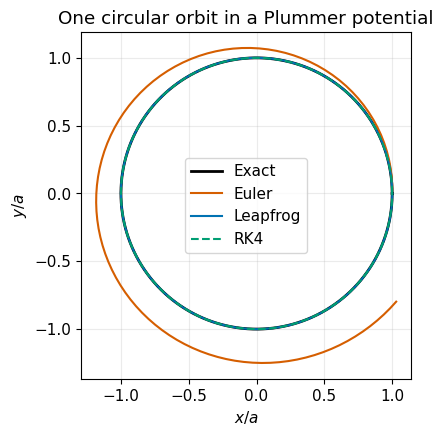

In [6]:
nstep = 100
dt = T0 / nstep

x_eu, v_eu = integrate_euler(acc_plummer_model, x0, v0, dt, nstep)
x_lf, v_lf = integrate_leapfrog(acc_plummer_model, x0, v0, dt, nstep)
x_rk, v_rk = integrate_rk4(acc_plummer_model, x0, v0, dt, nstep)

theta = np.linspace(0.0, 2.0*np.pi, 500)

fig, ax = plt.subplots()
ax.plot(r0*np.cos(theta)/a, r0*np.sin(theta)/a, color=OI["black"], lw=2, label="Exact")
ax.plot(x_eu[:, 0]/a, x_eu[:, 1]/a, color=OI["vermillion"], label="Euler")
ax.plot(x_lf[:, 0]/a, x_lf[:, 1]/a, color=OI["blue"], label="Leapfrog")
ax.plot(x_rk[:, 0]/a, x_rk[:, 1]/a, color=OI["green"], ls="--", label="RK4")
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_title("One circular orbit in a Plummer potential")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.25)
plt.show()



## 演習1：1つの円軌道

1. Euler 法では円軌道がどのように変形するでしょうか。
2. `nstep = 50`, `100`, `200` と変えて軌道を比較してください。
3. リープフロッグ法と RK4 では、同じ時間刻み数でどちらが解析解に近いでしょうか。
4. 「高精度であること」と「保存系の長時間積分に適していること」は同じ意味でしょうか。


# 5. 時間積分法の収束次数

円軌道を90度進んだ時刻 $T_0/4$ における位置は解析的に
$$
(x,y)=(0,r_0)
$$
です。

数値解の位置誤差
$$
\epsilon_x
=
\left|
\mathbf{x}_{\rm num}(T_0/4)
-
\mathbf{x}_{\rm exact}(T_0/4)
\right|
$$
を `np.linalg.norm` で測ります。ここでは $T_0/4$ を $N=20,40,80,160,320$ ステップに分けるため、$\Delta t=T_0/(4N)$ です。前節の1周期を分割する設定とは異なります。

期待される大域収束次数は、

| 方法 | 期待される次数 |
|---|---:|
| Euler 法 | 1 |
| リープフロッグ法 | 2 |
| RK4 | 4 |

です。

測定手順はテキスト第1章「収束次数の測定」の格子累積台形則の格子収束と同じで、格子幅を時間刻みに置き換えたものです。

In [7]:
N_values = np.array([20, 40, 80, 160, 320])
t_end = T0 / 4.0
x_exact_end = np.array([0.0, r0])

methods = {
    "Euler": integrate_euler,
    "Leapfrog": integrate_leapfrog,
    "RK4": integrate_rk4,
}

dt_values = t_end / N_values
errors = {}

for name, method in methods.items():
    err = []
    for N_i in N_values:
        dt_i = t_end / N_i
        x_i, v_i = method(acc_plummer_model, x0, v0, dt_i, int(N_i))
        err.append(np.linalg.norm(x_i[-1] - x_exact_end))
    errors[name] = np.array(err)

# 誤差 ε ∝ (dt)^p なら log ε = p log(dt) + 定数。
# np.polyfit(..., 1) は [傾き, 切片] を返すので、[0] が収束次数 p。
orders = {
    name: np.polyfit(np.log(dt_values), np.log(err), 1)[0]
    for name, err in errors.items()
}

for name in methods:
    print(f"{name:8s}: 測定した収束次数 = {orders[name]:.3f}")


Euler   : 測定した収束次数 = 0.991
Leapfrog: 測定した収束次数 = 2.000
RK4     : 測定した収束次数 = 4.038


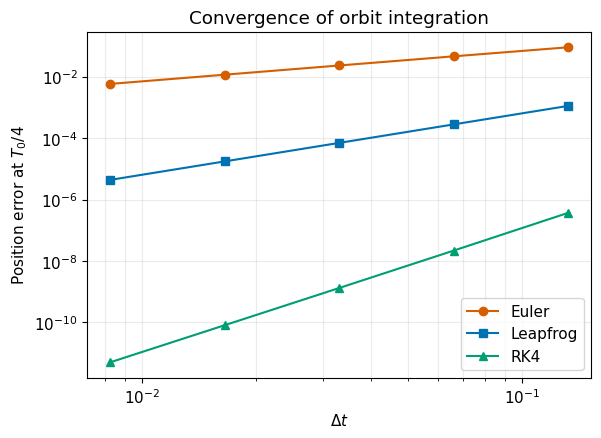

In [8]:
fig, ax = plt.subplots()
ax.loglog(dt_values, errors["Euler"], "o-", color=OI["vermillion"], label="Euler")
ax.loglog(dt_values, errors["Leapfrog"], "s-", color=OI["blue"], label="Leapfrog")
ax.loglog(dt_values, errors["RK4"], "^-", color=OI["green"], label="RK4")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel("Position error at $T_0/4$")
ax.set_title("Convergence of orbit integration")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()



## 演習2：収束性

1. 測定した収束次数が理論値 $1,2,4$ に近いことを確認してください。
2. 最も粗い時間刻みを除いて収束次数を再計算してください。
3. 同じ精度を得るために、各方法で必要な時間刻み数がどの程度違うか比較してください。
4. RK4 は1ステップあたり複数回の加速度評価を必要とします。精度だけでなく計算コストも考えて比較してください。



# 6. エネルギーと角運動量の保存

次に、円軌道ではなく離心軌道（eccentric orbit）を積分します。

球対称かつ時間に依存しないポテンシャルでは
$$
E=\mathrm{const.},
\qquad
L_z=\mathrm{const.}
$$
です。

したがって
$$
\frac{E(t)-E(0)}{|E(0)|},
\qquad
\frac{L_z(t)-L_z(0)}{|L_z(0)|}
$$
を数値診断量として使えます。初期条件は $\mathbf{x}_0=(1,0)$、$\mathbf{v}_0=(0,0.45)$ です。
$\Delta t=T_0/100$ で $20T_0$ まで、2000ステップを計算します。$T_0$ は円軌道の基準周期であり、ここで使う離心軌道の実測周期ではありません。

3手法の誤差の大きさを比べる図では、上の比の絶対値を対数目盛で表示します。誤差が0の点は対数表示できないのでマスクし、小さな正数への置き換えは行いません。エネルギーの符号付き誤差は、Euler 法を除いた拡大図でも確認します。

**自己重力系での保存量。** 保存量の選択は、解く問題によって変わる。
自己重力の $N$ 体計算では粒子間でエネルギーを交換するため、各粒子のエネルギーは一般には一定でない。
外力がなく、粒子質量が一定の孤立系では、系全体のエネルギーなどを保存量の診断に用いる（参考：富阪ほか編『シミュレーション天文学』）。
本章で各軌道のエネルギーを調べるのは、粒子が動いても変わらない、時間に依存しない重力場を与えているためです。


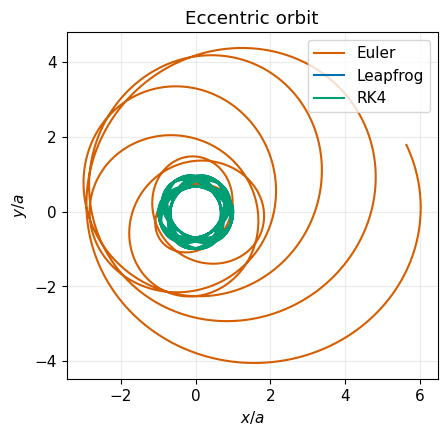

In [9]:
x0_e = np.array([1.0, 0.0])
v0_e = np.array([0.0, 0.45])

n_period = 20
steps_per_period = 100
dt = T0 / steps_per_period
nstep = n_period * steps_per_period
t = np.arange(nstep + 1) * dt

orbits = {}
for name, method in methods.items():
    x_i, v_i = method(acc_plummer_model, x0_e, v0_e, dt, nstep)
    E_i = energy_plummer(x_i, v_i, G, M, a)
    L_i = angular_momentum_z(x_i, v_i)
    orbits[name] = (x_i, v_i, E_i, L_i)

fig, ax = plt.subplots()
for name, color in [("Euler", OI["vermillion"]), ("Leapfrog", OI["blue"]), ("RK4", OI["green"])]:
    x_i = orbits[name][0]
    ax.plot(x_i[:, 0]/a, x_i[:, 1]/a, color=color, label=name)
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_title("Eccentric orbit")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


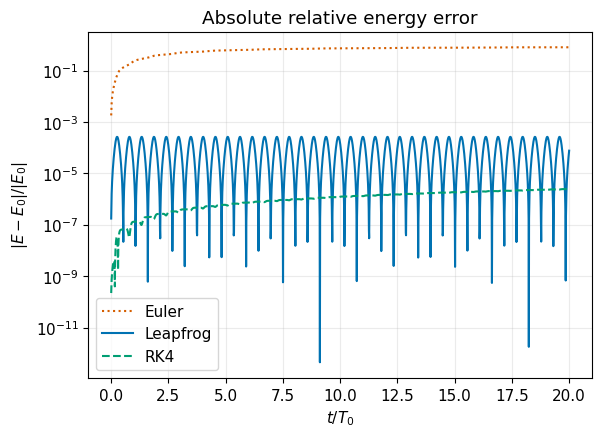

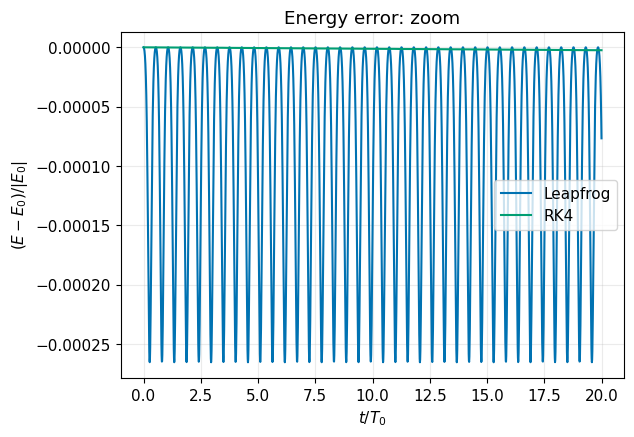

In [10]:
fig, ax = plt.subplots()
for name, color, ls in [("Euler", OI["vermillion"], ":"), ("Leapfrog", OI["blue"], "-"), ("RK4", OI["green"], "--")]:
    E_i = orbits[name][2]
    relE = (E_i - E_i[0]) / abs(E_i[0])
    abs_error = np.ma.masked_less_equal(np.abs(relE), 0.0)  # 0の点は表示しない。
    ax.semilogy(t / T0, abs_error, color=color, linestyle=ls, label=name)
ax.set_xlabel(r"$t/T_0$")
ax.set_ylabel(r"$|E-E_0|/|E_0|$")
ax.set_title("Absolute relative energy error")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
for name, color in [("Leapfrog", OI["blue"]), ("RK4", OI["green"])]:
    E_i = orbits[name][2]
    relE = (E_i - E_i[0]) / abs(E_i[0])
    ax.plot(t / T0, relE, color=color, label=name)
ax.set_xlabel(r"$t/T_0$")
ax.set_ylabel(r"$(E-E_0)/|E_0|$")
ax.set_title("Energy error: zoom")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


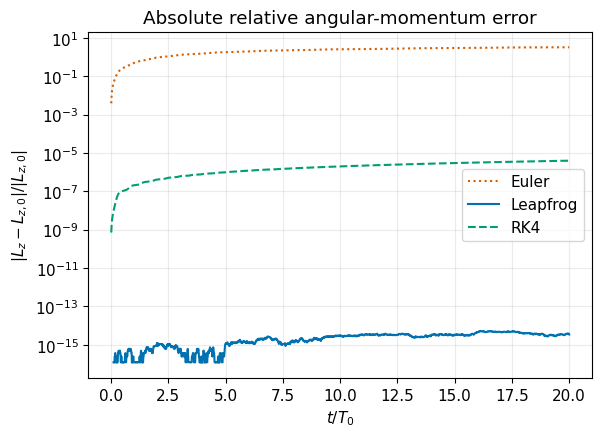

Euler   : 最大 |Delta E|/|E0| = 8.146912e-01, 最大 |Delta Lz|/|Lz0| = 3.293360e+00
Leapfrog: 最大 |Delta E|/|E0| = 2.654607e-04, 最大 |Delta Lz|/|Lz0| = 5.304399e-15
RK4     : 最大 |Delta E|/|E0| = 2.458288e-06, 最大 |Delta Lz|/|Lz0| = 3.999686e-06


In [11]:
fig, ax = plt.subplots()
for name, color, ls in [("Euler", OI["vermillion"], ":"), ("Leapfrog", OI["blue"], "-"), ("RK4", OI["green"], "--")]:
    L_i = orbits[name][3]
    relL = (L_i - L_i[0]) / abs(L_i[0])
    abs_error = np.ma.masked_less_equal(np.abs(relL), 0.0)  # 0の点は表示しない。
    ax.semilogy(t / T0, abs_error, color=color, linestyle=ls, label=name)
ax.set_xlabel(r"$t/T_0$")
ax.set_ylabel(r"$|L_z-L_{z,0}|/|L_{z,0}|$")
ax.set_title("Absolute relative angular-momentum error")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


# 保存済みの軌道から、全出力時刻の最大絶対相対変化を求める。
short_max_errors = {}
for name in methods:
    E_i, L_i = orbits[name][2:]
    max_E = np.max(np.abs((E_i - E_i[0]) / abs(E_i[0])))
    max_L = np.max(np.abs((L_i - L_i[0]) / abs(L_i[0])))
    short_max_errors[name] = {"energy": float(max_E), "Lz": float(max_L)}
    print(f"{name:8s}: 最大 |Delta E|/|E0| = {max_E:.6e}, 最大 |Delta Lz|/|Lz0| = {max_L:.6e}")


## 結果の解釈

Euler 法ではエネルギーと角運動量が大きくずれ、軌道が外側へ広がります。この条件では、最大エネルギー誤差は RK4 の方がリープフロッグ法より小さくなります。一方、リープフロッグ法の符号付き誤差は振動し、RK4 には長期的なずれが見られます。誤差の大きさと時間変化は分けて読んでください。

中心力では、キックによる角運動量の変化は
$$
\Delta\mathbf L_{\rm kick}=\frac{\Delta t}{2}\mathbf x\times\mathbf a(\mathbf x)=\mathbf 0
$$
です。加速度が位置ベクトルに平行だからです。ドリフトでは
$$
\Delta\mathbf L_{\rm drift}=\Delta t\,\mathbf v_{n+1/2}\times\mathbf v_{n+1/2}=\mathbf 0
$$
となります。このため、中心力ではリープフロッグ法の更新式が角運動量を数学的に保存します。実際の計算で見える非常に小さなずれは、浮動小数点演算によって生じます。ただし、角運動量が保存されても軌道位相（軌道上の位置を表す角度）に誤差があれば、同じ時刻の位置は解析解からずれます。位置の精度は、第5節の解析解との比較や時間刻みを変えた収束試験で確認します。

## 演習3：保存則

1. Euler 法のエネルギー誤差が時間とともに増加することを確認してください。
2. リープフロッグ法のエネルギー誤差が小さく振動することを確認してください。
3. RK4 とリープフロッグ法のエネルギー誤差の大きさと時間依存性を比較してください。
4. $L_z$ の保存性も比較してください。
5. 保存則を監視することが、軌道計算の検証に有効な理由を説明してください。



# 7. RK4 とリープフロッグ法の長時間挙動

高次の RK4 は短時間では非常に高精度です。一方、リープフロッグ法はシンプレクティックであり、保存系の長時間積分で異なる誤差構造を持ちます。

松本ほか §9.6 でも、重力多体系のリープフロッグ法について、エネルギー誤差が小さく振動しながら一方向にずれにくいことが説明されています。

ここでは比較的大きな時間刻みで長時間積分し、RK4 とリープフロッグ法の違いを見ます。第6節とは積分時間だけでなく、時間刻みも異なります。


積分時間は $1000T_0$、刻みは $T_0/50$ です。$T_0$ は先に定義した **半径 $r_0$ の円軌道の基準周期**であり、この離心軌道の実測周期ではありません。`n_period_long` は $T_0$ の倍数を表します。比較は同じ時間刻みであり、計算コストが等しい比較ではありません。


振動する誤差の最終値は、計算を止めた位相で変わります。そこで、最終値に加えて、出力時刻での最大絶対相対変化も測ります。
$$
\epsilon_{E,\max}(T)=\max_{0\le t_n\le T}\frac{|E(t_n)-E(0)|}{|E(0)|}.
$$
時間経過の影響だけを見るため、同じ $\Delta t=T_0/50$ の計算の最初の $20T_0$ と、全体の $1000T_0$ を比較します。短時間の図は別の計算ではなく、長時間計算の初期部分を取り出したものです。


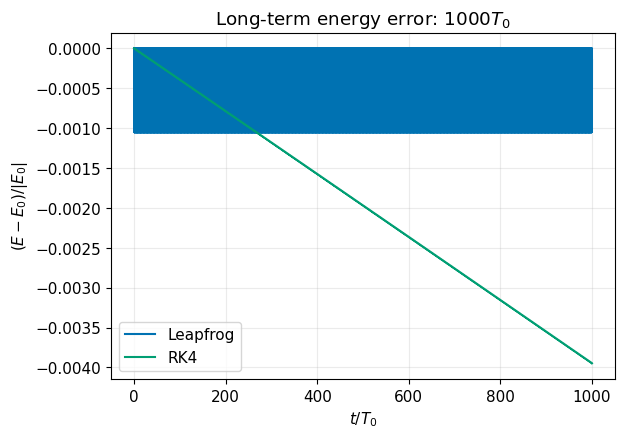

リープフロッグ法の最終エネルギー誤差 = -1.497779e-04
RK4 の最終エネルギー誤差     = -3.947600e-03
Leapfrog: 最大 |Delta E|/|E0|, 20T0まで = 1.054793e-03, 1000T0まで = 1.054795e-03
RK4     : 最大 |Delta E|/|E0|, 20T0まで = 7.822273e-05, 1000T0まで = 3.947600e-03


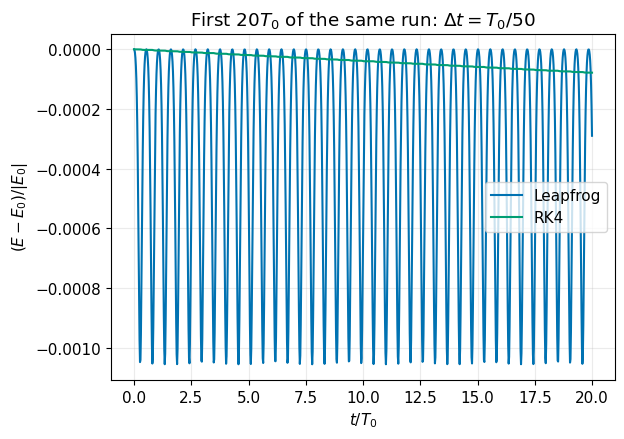

In [12]:
n_period_long = 1000
steps_per_period_long = 50
dt_long = T0 / steps_per_period_long
nstep_long = n_period_long * steps_per_period_long
t_long = np.arange(nstep_long + 1) * dt_long

long_results = {}
for name, method in [("Leapfrog", integrate_leapfrog), ("RK4", integrate_rk4)]:
    x_i, v_i = method(acc_plummer_model, x0_e, v0_e, dt_long, nstep_long)
    E_i = energy_plummer(x_i, v_i, G, M, a)
    long_results[name] = (E_i - E_i[0]) / abs(E_i[0])

fig, ax = plt.subplots()
ax.plot(t_long / T0, long_results["Leapfrog"], color=OI["blue"], label="Leapfrog")
ax.plot(t_long / T0, long_results["RK4"], color=OI["green"], label="RK4")
ax.set_xlabel(r"$t/T_0$")
ax.set_ylabel(r"$(E-E_0)/|E_0|$")
ax.set_title(r"Long-term energy error: $1000T_0$")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

print(f"リープフロッグ法の最終エネルギー誤差 = {long_results['Leapfrog'][-1]:.6e}")
print(f"RK4 の最終エネルギー誤差     = {long_results['RK4'][-1]:.6e}")


# 同じ長時間計算の最初の20T0と全体を比較する（時間刻みは共通）。
n_early = min(nstep_long, 20 * steps_per_period_long)
long_max_errors = {}
for name in ["Leapfrog", "RK4"]:
    err = long_results[name]
    max_early = np.max(np.abs(err[:n_early + 1]))
    max_all = np.max(np.abs(err))
    long_max_errors[name] = {"early": float(max_early), "all": float(max_all)}
    print(f"{name:8s}: 最大 |Delta E|/|E0|, 20T0まで = {max_early:.6e}, 1000T0まで = {max_all:.6e}")

fig, ax = plt.subplots()
for name, color in [("Leapfrog", OI["blue"]), ("RK4", OI["green"])]:
    ax.plot(t_long[:n_early + 1] / T0, long_results[name][:n_early + 1], color=color, label=name)
ax.set_xlabel(r"$t/T_0$")
ax.set_ylabel(r"$(E-E_0)/|E_0|$")
ax.set_title(r"First $20T_0$ of the same run: $\Delta t=T_0/50$")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 長時間比較の読み方

この条件では、リープフロッグ法の最大誤差は最初の $20T_0$ と全体でほとんど変わりません。RK4 の誤差は初めは小さいものの、長期的にずれていきます。ただし、大小が入れ替わる時刻は時間刻みに強く依存します。例えば $\Delta t=T_0/100$ では、$1000T_0$ まで積分しても RK4 の最大誤差の方が小さいままです。誤差の大小を比べるときは、時間刻みと積分時間を必ず併記し、最大誤差と符号付き誤差の両方を調べてください。

ここまでが第3章の基本学習に対応します。以下は、時間積分法の性質と他分野での使い方についての補足です。

## 補足：シンプレクティック積分法

Hamilton 系の位相空間構造を離散時間発展でも保つ積分法を、シンプレクティック積分法と呼びます。リープフロッグ法はその一例です。ここでは、時間に依存しない保存力と固定時間刻みを前提にしています。

物理的エネルギーを各ステップで厳密に保存するわけではありません。十分小さい刻みで滑らかな束縛軌道を積分するとき、エネルギー誤差が一方向へ蓄積しにくいことと、任意の刻みでも安定であることは別です。精度の次数とも区別してください。

実際の $N$ 体計算や SPH 計算では、粒子の状態に応じた**可変時間刻み（adaptive timestep）**や、粒子ごとに異なる時間刻み（**独立時間刻み; individual timestep**）を用いる場合がある。
その場合、本章の共通の固定時間刻みで見た長時間の保存性はそのままでは保証されず、時間刻みの決め方と更新手順を組み合わせた検証が必要になる。


## 補足：宇宙流体計算の時間積分 — RK2 と RK3

例えば有限体積法では、密度・運動量密度・エネルギー密度などのセル平均値を持たせます。空間方向を離散化すると、それらをまとめた $\mathbf U$ の時間発展は $d\mathbf U/dt=\mathbf f(\mathbf U)$ と書けます。$\mathbf f$ は現在の状態からセル境界を通る流束や重力などの効果を評価し、各セルの時間変化率を計算する関数です。

2次精度の Heun 法は
$$
\begin{aligned}
\mathbf U^{(1)}&=\mathbf U^n+\Delta t\,\mathbf f(\mathbf U^n),\\
\mathbf U^{n+1}&=\tfrac12\mathbf U^n+\tfrac12[\mathbf U^{(1)}+\Delta t\,\mathbf f(\mathbf U^{(1)})]
\end{aligned}
$$
です。代表的な3次精度の公式では、最初の予測値 $\mathbf U^{(1)}$ は共通ですが、その後を
$$
\begin{aligned}
\mathbf U^{(2)}&=\tfrac34\mathbf U^n+\tfrac14[\mathbf U^{(1)}+\Delta t\,\mathbf f(\mathbf U^{(1)})],\\
\mathbf U^{n+1}&=\tfrac13\mathbf U^n+\tfrac23[\mathbf U^{(2)}+\Delta t\,\mathbf f(\mathbf U^{(2)})]
\end{aligned}
$$
とします。ここで示した RK2 では2回、RK3 では3回、右辺を評価します。軌道計算の手法との関係は、藤井・立川『Pythonで学ぶ流体力学の数値計算法』、松本ほか『輻射電磁流体シミュレーションの基礎』を参照してください。

SPH 法では圧力による力や熱的な量の更新も必要です。速度に依存する力や散逸を含む場合には、今回の保存力と固定時間刻みに対するリープフロッグ法の保存性を、そのまま適用できるとは限りません。RK2・RK3も空間離散化と組み合わせた時間刻みの制約を満たす必要があります。


# まとめ

Plummer 球の解析的な加速度を使い、Euler 法・リープフロッグ法・RK4 の大域収束次数を、円軌道の解析解からそれぞれ約1次・約2次・約4次と測定しました。円軌道以外では $E$ と $L_z$ を数値診断量として使いました。

Notebook 1〜3で、同じ球対称モデルについて数値積分、有限差分・数値微分、時間積分を学びました。各手法の誤差を分けるため、本 Notebook では解析的な加速度を入力しています。ここまでで本編の基礎学習を終えます。さらに学ぶ場合には、Notebook Bで2次元の重力場計算、Notebook Cで軸対称・非軸対称ポテンシャルへの時間積分法の適用を扱います。
